<a href="https://colab.research.google.com/github/Kauustubbh/DocForgery/blob/main/notebooks/01_data_exploration_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Cell 1: Download Images (Kaggle) & Ground-Truth Masks (GitHub)
*Downloads the CASIA images via Kaggle and clones the official ground-truth mask repository directly into your local /content/data/ scratchpad.*

In [1]:
# Cell 1: Download Images & Ground-Truth Masks
import os
from google.colab import userdata

# Authenticate with Kaggle API using Colab Secret
os.environ['KAGGLE_API_TOKEN'] = userdata.get('Kaggle_api_key')

# 1. Download and extract CASIA images from Kaggle
!kaggle datasets download -d sophatvathana/casia-dataset
!unzip -q casia-dataset.zip -d data/

# 2. Download and extract official CASIA 2.0 Groundtruth masks (~25 MB)
!git clone --depth 1 https://github.com/namtpham/casia2groundtruth.git data/casia2_gt
!unzip -q data/casia2_gt/CASIA2.0_Groundtruth.zip -d data/CASIA2_Groundtruth/

print("✓ Images and ground-truth masks extracted successfully.")
!ls data/

Dataset URL: https://www.kaggle.com/datasets/sophatvathana/casia-dataset
License(s): unknown
100% 5.22G/5.22G [01:05<00:00, 85.7MB/s]

Cloning into 'data/casia2_gt'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 1), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 4.26 MiB | 31.19 MiB/s, done.
Resolving deltas: 100% (1/1), done.
✓ Images and ground-truth masks extracted successfully.
casia  CASIA1  CASIA2  CASIA2_Groundtruth  casia2_gt


## Cell 2: Mount Google Drive

In [2]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Link persistent project paths
PROJECT_DIR = '/content/drive/MyDrive/DocForgery'
PROCESSED_DIR = os.path.join(PROJECT_DIR, 'processed')
CHECKPOINTS_DIR = os.path.join(PROJECT_DIR, 'checkpoints')

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(CHECKPOINTS_DIR, exist_ok=True)

print(f"Project directory ready at: {PROJECT_DIR}")
print(f"Processed directory: {PROCESSED_DIR}")
print(f"Checkpoints directory: {CHECKPOINTS_DIR}")

Mounted at /content/drive
Project directory ready at: /content/drive/MyDrive/DocForgery
Processed directory: /content/drive/MyDrive/DocForgery/processed
Checkpoints directory: /content/drive/MyDrive/DocForgery/checkpoints


## Cell 3: Imports

In [3]:
import glob
import io
import os
import cv2
from PIL import Image, ImageChops, ImageEnhance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Set visualization styles
sns.set_theme(style='whitegrid')
plt.rcParams['figure.autolayout'] = True

## Cell 4: File Discovery, Mask Pairing & DataFrame Creation
*Scans the directories, performs case-insensitive stem matching between tampered images and ground-truth masks, and compiles the master metadata DataFrame.*

In [4]:
# Cell 4: File Discovery and Image-Mask Pairing
# Gather authentic, tampered, and mask file paths
au_paths = glob.glob('data/**/CASIA2/Au/*', recursive=True) + glob.glob('data/CASIA2/Au/*')
tp_paths = glob.glob('data/**/CASIA2/Tp/*', recursive=True) + glob.glob('data/CASIA2/Tp/*')
gt_paths = glob.glob('data/CASIA2_Groundtruth/**/*.*', recursive=True)

valid_exts = ('.jpg', '.jpeg', '.png', '.tif', '.bmp')
au_files = [p for p in au_paths if p.lower().endswith(valid_exts)]
tp_files = [p for p in tp_paths if p.lower().endswith(valid_exts)]
gt_files = [p for p in gt_paths if p.lower().endswith(valid_exts)]

# Case-insensitive lookup dictionary for ground-truth masks
gt_lookup = {}
for p in gt_files:
    stem = os.path.splitext(os.path.basename(p))[0]
    clean_stem = stem.replace('_gt', '').replace('gt_', '').replace('_GT', '').lower()
    gt_lookup[clean_stem] = p

records = []

# 1. Authentic Images (label = 0, mask_path = None)
for p in au_files:
    img_id = os.path.splitext(os.path.basename(p))[0]
    records.append({
        'image_id': img_id,
        'image_path': p,
        'mask_path': None,
        'label': 0,
        'forgery_type': 'authentic'
    })

# 2. Tampered Images (label = 1, mask_path = matched path or None)
for p in tp_files:
    basename = os.path.basename(p)
    img_id = os.path.splitext(basename)[0]
    clean_stem = img_id.replace('_gt', '').replace('gt_', '').replace('_GT', '').lower()

    f_type = 'splicing' if ('_s_' in basename.lower()) else 'copy_move'

    records.append({
        'image_id': img_id,
        'image_path': p,
        'mask_path': gt_lookup.get(clean_stem, None),
        'label': 1,
        'forgery_type': f_type
    })

# Deduplicate records by unique image_id
df = pd.DataFrame(records).drop_duplicates(subset=['image_id']).reset_index(drop=True)

print(f"Dataset shape: {df.shape}")
print(f"Total Authentic: {(df['label'] == 0).sum()}")
print(f"Total Tampered:  {(df['label'] == 1).sum()}")
print(f"Tampered with Matched Masks: {((df['label'] == 1) & (df['mask_path'].notnull())).sum()}")
df.head()

Dataset shape: (12614, 5)
Total Authentic: 7491
Total Tampered:  5123
Tampered with Matched Masks: 4979


,image_id,image_path,mask_path,label,forgery_type
0,Au_art_30225,data/CASIA2/Au/Au_art_30225.jpg,None,0,authentic
1,Au_nat_20070,data/CASIA2/Au/Au_nat_20070.jpg,None,0,authentic
2,Au_sec_30662,data/CASIA2/Au/Au_sec_30662.jpg,None,0,authentic
3,Au_art_30413,data/CASIA2/Au/Au_art_30413.jpg,None,0,authentic
4,Au_sec_30682,data/CASIA2/Au/Au_sec_30682.jpg,None,0,authentic


Cell 5: Missing Values & Data Integrity Check

In [5]:
print("Missing values per column:")
print(df.isnull().sum())

tp_count = (df['label'] == 1).sum()
tp_matched = ((df['label'] == 1) & (df['mask_path'].notnull())).sum()
print(f"\nMask matching rate: {tp_matched} / {tp_count} ({tp_matched / tp_count * 100:.1f}%)")

Missing values per column:
image_id           0
image_path         0
mask_path       7635
label              0
forgery_type       0
dtype: int64

Mask matching rate: 4979 / 5123 (97.2%)


## Cell 6: Map Labels to Full Descriptive Names
*Adds readable classification and manipulation strings.*

In [6]:
label_names = {
    0: 'Authentic Document',
    1: 'Tampered Document'
}

forgery_full_names = {
    'authentic': 'Authentic / Untouched',
    'splicing': 'Image Splicing',
    'copy_move': 'Copy-Move Forgery'
}

df['label_name'] = df['label'].map(label_names)
df['forgery_full'] = df['forgery_type'].map(forgery_full_names)
df[['image_id', 'label', 'label_name', 'forgery_type', 'forgery_full']].head()

,image_id,label,label_name,forgery_type,forgery_full
0,Au_art_30225,0,Authentic Document,authentic,Authentic / Untouched
1,Au_nat_20070,0,Authentic Document,authentic,Authentic / Untouched
2,Au_sec_30662,0,Authentic Document,authentic,Authentic / Untouched
3,Au_art_30413,0,Authentic Document,authentic,Authentic / Untouched
4,Au_sec_30682,0,Authentic Document,authentic,Authentic / Untouched


## Cell 7: Visualize Class & Forgery Distribution
*Generates countplots and summary percentage tables.*

/tmp/ipykernel_1803/2825373538.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='label_name', order=order_binary, palette='viridis', ax=axes[0])
/tmp/ipykernel_1803/2825373538.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='forgery_full', order=order_subtypes, palette='magma', ax=axes[1])


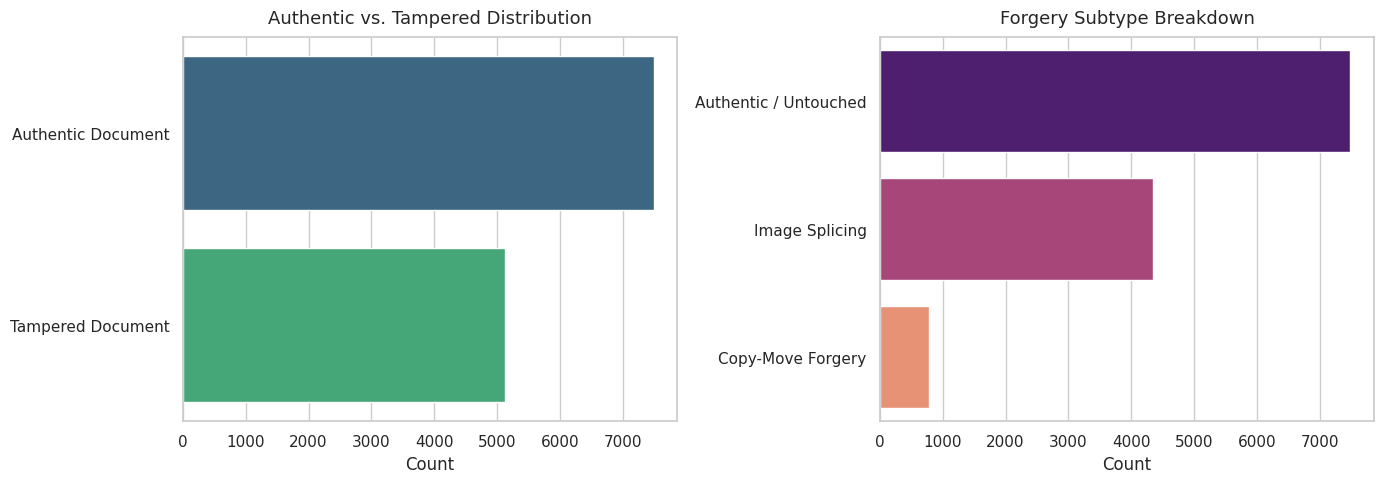

                       Count  Percentage (%)
forgery_full                                
Authentic / Untouched   7491           59.39
Image Splicing          4341           34.41
Copy-Move Forgery        782            6.20


In [7]:
# Class Distribution Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_binary = df['label_name'].value_counts().index
sns.countplot(data=df, y='label_name', order=order_binary, palette='viridis', ax=axes[0])
axes[0].set_title('Authentic vs. Tampered Distribution', fontsize=13, pad=10)
axes[0].set_xlabel('Count')
axes[0].set_ylabel('')

order_subtypes = df['forgery_full'].value_counts().index
sns.countplot(data=df, y='forgery_full', order=order_subtypes, palette='magma', ax=axes[1])
axes[1].set_title('Forgery Subtype Breakdown', fontsize=13, pad=10)
axes[1].set_xlabel('Count')
axes[1].set_ylabel('')

plt.show()

# Exact distribution summary
percentages = df['forgery_full'].value_counts(normalize=True) * 100
counts = df['forgery_full'].value_counts()
dist_summary = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages.round(2)})
print(dist_summary)

## Cell 8: Build Sample Inspection Grid with ELA
Computes the Error Level Analysis (ELA) map and plots a 4-column inspection grid:

Original RGB image

Error Level Analysis (ELA) map

Ground-Truth Mask

Tamper Overlay (red tint on forged regions)


Displaying Authentic Document:


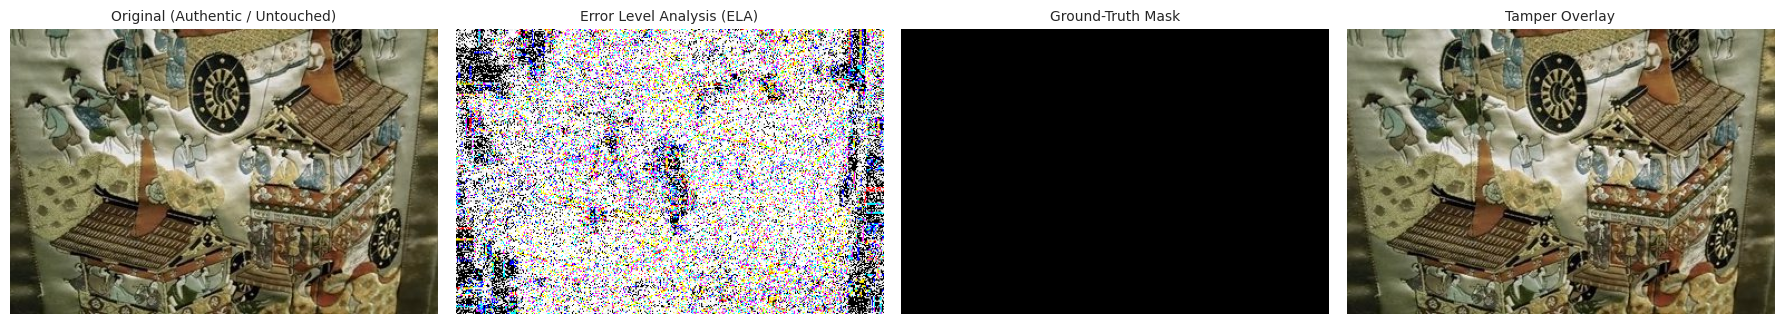

Displaying Tampered Document:


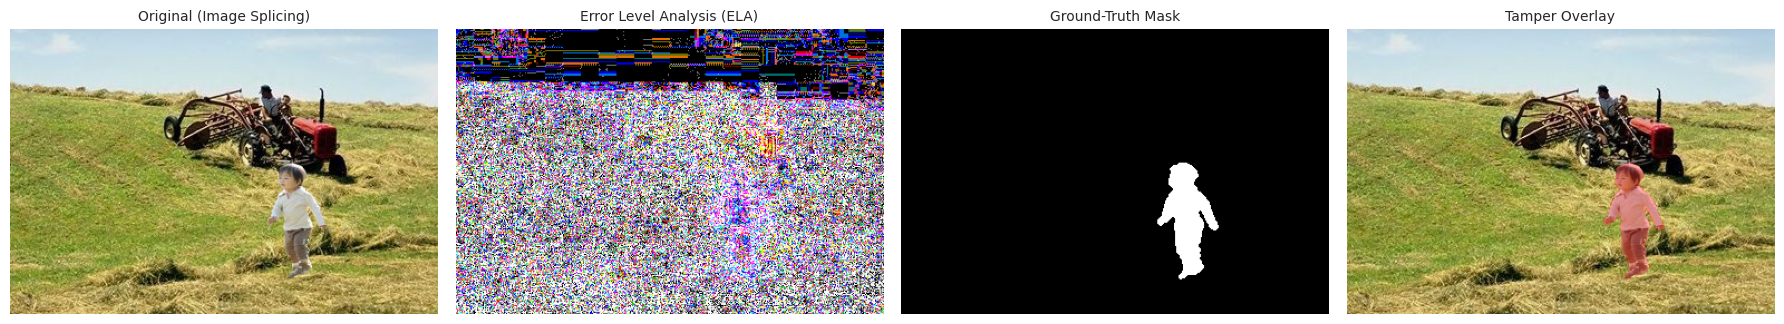

In [8]:
# Error Level Analysis & Sample Inspection Grid
def generate_ela(image_path: str, quality: int = 90, scale: float = 15.0) -> np.ndarray:
    """Computes JPEG compression error distribution (ELA)."""
    original = Image.open(image_path).convert('RGB')
    buffer = io.BytesIO()
    original.save(buffer, 'JPEG', quality=quality)
    buffer.seek(0)
    compressed = Image.open(buffer)

    ela_diff = ImageChops.difference(original, compressed)
    extrema = ela_diff.getextrema()
    max_diff = max([ex[1] for ex in extrema])
    scale_factor = scale * (255.0 / (max_diff if max_diff != 0 else 1.0))

    enhancer = ImageEnhance.Brightness(ela_diff)
    return np.array(enhancer.enhance(scale_factor))

def plot_inspection_grid(sample_row: pd.Series) -> None:
    img = cv2.imread(sample_row['image_path'])
    if img is None:
        print(f"Error loading image: {sample_row['image_path']}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    ela = generate_ela(sample_row['image_path'])

    # Load mask or generate blank authentic mask
    if sample_row['mask_path'] and os.path.exists(str(sample_row['mask_path'])):
        mask = cv2.imread(sample_row['mask_path'], cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 128).astype(np.uint8) * 255
    else:
        mask = np.zeros((h, w), dtype=np.uint8)

    overlay = img.copy()
    overlay[mask > 0] = [255, 0, 0]
    blended = cv2.addWeighted(img, 0.7, overlay, 0.3, 0)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    axes[0].imshow(img)
    axes[0].set_title(f"Original ({sample_row['forgery_full']})", fontsize=10)
    axes[1].imshow(ela)
    axes[1].set_title("Error Level Analysis (ELA)", fontsize=10)
    axes[2].imshow(mask, cmap='gray')
    axes[2].set_title("Ground-Truth Mask", fontsize=10)
    axes[3].imshow(blended)
    axes[3].set_title("Tamper Overlay", fontsize=10)

    for ax in axes:
        ax.axis('off')
    plt.show()

# Display sample authentic and tampered items
sample_auth = df[df['label'] == 0].iloc[0]
sample_tamp = df[(df['label'] == 1) & (df['mask_path'].notnull())].iloc[0]

print("Displaying Authentic Document:")
plot_inspection_grid(sample_auth)

print("Displaying Tampered Document:")
plot_inspection_grid(sample_tamp)

## Cell 9: Balanced Stratified Split & Manifest Export to Google Drive
Creates a balanced subset (1,500 Authentic and 1,500 Tampered samples with masks) to maintain a fast 20–30 minute training cycle, applies a 70/15/15 stratified split, and writes metadata.csv to Google Drive.

In [9]:
# Balanced Train / Val / Test Split & Manifest Export
df_tampered_valid = df[(df['label'] == 1) & (df['mask_path'].notnull())]
df_authentic_valid = df[df['label'] == 0]

# Subsample 1,500 authentic and 1,500 tampered for 20-30 min baseline training
SAMPLE_SIZE = min(1500, len(df_tampered_valid), len(df_authentic_valid))

df_balanced = pd.concat([
    df_authentic_valid.sample(n=SAMPLE_SIZE, random_state=42),
    df_tampered_valid.sample(n=SAMPLE_SIZE, random_state=42)
]).sample(frac=1.0, random_state=42).reset_index(drop=True)

# 70% Train, 15% Validation, 15% Test
train_df, temp_df = train_test_split(
    df_balanced,
    test_size=0.30,
    random_state=42,
    stratify=df_balanced['label']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label']
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df['split'] = 'train'
val_df['split'] = 'val'
test_df['split'] = 'test'

df_final = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

# Export metadata.csv to Google Drive
manifest_path = os.path.join(PROCESSED_DIR, 'metadata.csv')
export_cols = ['image_id', 'image_path', 'mask_path', 'label', 'label_name', 'forgery_type', 'forgery_full', 'split']
df_final[export_cols].to_csv(manifest_path, index=False)

print(f"✓ Manifest successfully exported to: {manifest_path}")
print("\nSamples per Split and Class:")
print(df_final.groupby(['split', 'label_name']).size().unstack())

✓ Manifest successfully exported to: /content/drive/MyDrive/DocForgery/processed/metadata.csv

Samples per Split and Class:
label_name  Authentic Document  Tampered Document
split                                            
test                       225                225
train                     1050               1050
val                        225                225
